# Figure 2 — methods explainer

One lake, from ICESat-2 photons to a Sentinel-2 meltwater volume.

| panel | shows |
|---|---|
| (a) | the 424 ICESat-2 reference ground tracks over Greenland, with this lake marked |
| (b) | Sentinel-2 true colour, the ground track, and the in-water lake segment |
| (c) | ATL03 photons with the FLUID/SuRRF surface and lakebed fits — **the target variable** |
| (d) | the 16 Sentinel-2 predictors along the same track — **the predictors** |
| (e) | the random forest applied to every pixel of the chip |

Panels (c) and (d) together are this lake's contribution to the training set.

### Inputs

All under `data/`, so the notebook is self-contained:

* `data/is2/<lake_id>.h5` — the FLUID/SuRRF output for this segment
* `data/fig2/lake_094135_s2_10m_00_info.tif` — the 18-band Sentinel-2 chip
* `data/fig2/lake_094135_depth_pred_rfe_noangle.tif` — the 16-predictor model applied to it
* `data/fig2/lake_094135_predictors.csv` — this lake's 562 training rows
* `data/fig2/feature_importance_rfe16.csv` — held-out permutation importance
* `data/fig2/training_set_size.json` — row and lake counts for the whole training set
* `data/shapefiles/` — basins, coastline, reference ground tracks

The last four were extracted from `zenodo_build/` by
`zenodo_build/scripts/feature_importance.py` and the staging step in the session notes
(§10.7); regenerate them there if the training set or the model changes.

### Caption note

Area and volume in (e) are **chip totals**. The thresholded chip holds 16 connected
components; the lake itself is 99 % of the volume and the rest are small separate ponds.


In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import json
import shutil

import geopandas as gpd
import h5py
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from cmcrameri import cm as cmc
from IPython.display import Image, display
from matplotlib.colors import Normalize
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from scipy import ndimage

# The other figure notebooks render through LaTeX. Fall back to mathtext where no TeX install
# is on PATH, so the notebook still runs; the figure then differs only in how maths is set.
#
# NB on 'Optima': under text.usetex matplotlib accepts only serif / sans-serif / cursive /
# monospace and silently falls back to serif -- i.e. Computer Modern -- for anything else.
# That is why figures 3-6 are set in Computer Modern even though they all ask for Optima
# (their PDFs embed CMR/CMBX/CMMI/SFRM and no Optima at all). The setting is kept here so
# this figure matches them; it only takes effect in the mathtext fallback below.
USETEX = shutil.which('latex') is not None
plt.rcParams.update({'font.size': 9, 'font.family': 'Optima', 'text.usetex': USETEX})
print('text.usetex:', USETEX)

_TEX_UNSAFE = (('\u00f8', r'\o{}'), ('\u2013', '--'), ('\u2019', "'"),
               ('\u2212', '$-$'), ('\u00b7', r'$\cdot$'), ('%', r'\%'))


def bold(s):
    """Embolden a title. Under text.usetex matplotlib ignores the fontweight property, so
    the weight has to be requested from LaTeX; in the mathtext fallback the property works."""
    return r'\textbf{%s}' % s if USETEX else s


def tex(s):
    """Make a plain-text label safe for text.usetex, which chokes on these characters raw."""
    if not USETEX:
        return s
    for raw, escaped in _TEX_UNSAFE:
        s = s.replace(raw, escaped)
    return s


text.usetex: True


In [2]:
LID = ('lake_094135_GrIS_2021_simplified_GRE_2200_NE_ATL03_20210720053125_04061205'
       '_006_01_gt3r_0045')
RGT = 406                       # ATL03_<time>_RRRRCCSS_...  ->  0406
GTX = LID.split('_')[-2].upper()

H5    = f'data/is2/{LID}.h5'
CHIP  = 'data/fig2/lake_094135_s2_10m_00_info.tif'
PRED  = 'data/fig2/lake_094135_depth_pred_rfe_noangle.tif'
PREDS = 'data/fig2/lake_094135_predictors.csv'
IMP   = 'data/fig2/feature_importance_rfe16.csv'
SIZES = 'data/fig2/training_set_size.json'
SHP   = 'data/shapefiles'

CONF_MIN  = 0.3      # bathymetry confidence threshold used throughout the paper
DEPTH_MIN = 0.1      # m, minimum predicted depth counted as water
MIN_BLOB  = 10       # px; drops isolated speckle from the water mask (10 px = 1000 m2)
VMAX      = 11.0     # m, depth colour scale
PAD_FRAC  = 0.12     # margin around the lake before the trim
TRIM      = 0.95     # slight crop; the window is already tight around the lake
REFRACT   = 1.336    # refractive index of 532 nm light in 0 C freshwater (Mobley, 1995)
Y_DROP    = 9.0      # m below the deepest lake photon, leaving room for the confidence strip
GREEN_532 = '#16a81e'   # ICESat-2's 532 nm laser
RED, BLUE = '#d62728', '#1f77b4'

# ---------------------------------------------------------------- ICESat-2 along-track
with h5py.File(H5, 'r') as f:
    ph = pd.DataFrame({k: f['photon_data'][k][()] for k in
                       ('xatc', 'h', 'snr', 'prob_surf', 'prob_bed')})
    dp = pd.DataFrame({k: f['depth_data'][k][()] for k in
                       ('xatc', 'lat', 'lon', 'depth', 'conf', 'h_fit_surf', 'h_fit_bed')})
    H0 = float(f['properties']['surface_elevation'][()])
    SURF_EXT = np.asarray(f['properties']['surface_extent_detection'][()], dtype=float)

# Re-zero along-track distance on the first depth sample. The Sentinel-2 predictors only exist
# where SuRRF produced a depth, so panels (c) and (d) are clipped to that span, and this makes
# the shared axis start at 0 there rather than at the first photon ~90 m earlier.
XOFF = float(dp.xatc.min())
ph['xatc'] -= XOFF
dp['xatc'] -= XOFF
SURF_EXT -= XOFF

wet = dp[(dp.depth > 0) & (dp.conf > CONF_MIN)]

# Heights in the archive are *apparent* - uncorrected for refraction. SuRRF defines
# depth = clip(surface_elevation - h_fit, 0, None) / 1.336, so check that before building the
# secondary depth axis on top of it.
ratio = (H0 - wet.h_fit_bed) / wet.depth
assert abs(np.median(ratio) - REFRACT) < 1e-3, \
    f'depth is not (surface - bed)/{REFRACT}: median ratio {np.median(ratio):.4f}'
print(f'refraction check: median (H0 - h_fit_bed)/depth = {np.median(ratio):.5f}')

MAX_DEPTH = wet.depth.max()
MAX_DEPTH_X = wet.xatc.iloc[int(np.argmax(wet.depth.to_numpy()))]
LEN_SURF_KM = (SURF_EXT[1] - SURF_EXT[0]) / 1000

# ---------------------------------------------------------------- rasters
with rasterio.open(CHIP) as r:
    rgb = np.moveaxis(r.read([4, 3, 2]), 0, -1).astype(float)
    chip_ext = (r.bounds.left, r.bounds.right, r.bounds.bottom, r.bounds.top)
    g = gpd.GeoDataFrame(dp, geometry=gpd.points_from_xy(dp.lon, dp.lat),
                         crs='EPSG:4326').to_crs(r.crs)
with rasterio.open(PRED) as r:
    depth_grid = r.read(1)
    px_area = abs(r.transform.a * r.transform.e)
    pred_transform = r.transform
rgb = np.clip(rgb / np.nanpercentile(rgb, 99), 0, 1) ** 0.85
g['x'], g['y'] = g.geometry.x, g.geometry.y

water_raw = depth_grid > DEPTH_MIN
lab, n_blobs = ndimage.label(water_raw)
sizes = np.bincount(lab.ravel())
water = water_raw & np.isin(lab, np.flatnonzero(sizes >= MIN_BLOB))
vol, area = np.nansum(depth_grid[water]) * px_area, water.sum() * px_area
# 16 components survive the size filter, but one of them is the lake: it holds 99 % of the
# volume, the rest are small separate ponds across the chip. Framing follows the lake,
# otherwise those outliers set the bounding box and shrink the lake in frame. The quoted area
# and volume stay chip totals.
sizes[0] = 0
main = water & (lab == int(np.argmax(sizes)))
print(f'water mask: {water_raw.sum():,} -> {water.sum():,} px in '
      f'{int((sizes >= MIN_BLOB).sum())} components; area {area/1e6:.2f} km2, '
      f'volume {vol/1e6:.2f} x10^6 m3, of which the lake itself is '
      f'{np.nansum(depth_grid[main]) * px_area / vol * 100:.1f}%')

# ---------------------------------------------------------------- predictors + importance
imp = pd.read_csv(IMP).sort_values('imp_perm_dmae', ascending=False).reset_index(drop=True)
# ln AOT and ln B2 both round to 0.02; put the constant row last, where it reads better
imp = pd.concat([imp[imp.feature != 'AOT_log'], imp[imp.feature == 'AOT_log']],
                ignore_index=True)
feats = imp.feature.tolist()
sizes_json = json.load(open(SIZES))
N_TRAIN, N_LAKES = sizes_json['n_training_rows'], sizes_json['n_training_lakes']

tl = pd.read_csv(PREDS).sort_values('xatc').reset_index(drop=True)
tl['xatc_ph'] = tl.xatc + (dp.xatc.min() - tl.xatc.min())
in_lake = (tl.depth > 0).to_numpy()
XLIM = (float(tl.xatc_ph.min()), float(tl.xatc_ph.max()))
print(f'{len(tl)} training rows of {N_TRAIN:,} from {N_LAKES:,} lakes; '
      f'panels (c)+(d) span {XLIM[0]:.0f}-{XLIM[1]:.0f} m')

# Each predictor is stretched onto the 2nd-98th percentile range of its *in-lake* values, so
# the panel shows structure within the lake rather than only the ice/water step. Bare-ice rows
# therefore saturate at one end. Absolute values are not comparable between rows.
M = tl[feats].to_numpy(float).T
lo = np.nanpercentile(M[:, in_lake], 2, axis=1, keepdims=True)
hi = np.nanpercentile(M[:, in_lake], 98, axis=1, keepdims=True)
Mn = np.clip((M - lo) / np.where(hi - lo == 0, np.nan, hi - lo), 0, 1)


def signchar(f):
    """Sign of the within-lake correlation with depth; a dot where it is undefined.

    The constancy test is on the peak-to-peak range, not on the standard deviation: for an
    exactly constant column `np.nanstd` still returns ~1e-16 (float64) or ~1e-6 (float32),
    because the two-pass mean it subtracts is not bit-exact. Testing `std == 0` therefore
    never fires, `corrcoef` returns a finite value built from rounding noise, and the panel
    ends up asserting a sign for a predictor that does not vary at all.
    """
    v, d = tl.loc[in_lake, f].to_numpy(), tl.loc[in_lake, 'depth'].to_numpy()
    spread = np.nanmax(v) - np.nanmin(v)
    if not np.isfinite(spread) or spread <= 1e-12 * max(np.nanmax(np.abs(v)), 1.0):
        return '\u00b7'
    with np.errstate(invalid='ignore'):
        r = np.corrcoef(v, d)[0, 1]
    return '\u00b7' if not np.isfinite(r) else ('+' if r > 0 else '\u2212')


# Differences of logarithms are written as differences, to match the manuscript. Note that
# ln(Bx)/ln(By) is a ratio OF logarithms and is a different quantity.
PRETTY = {'ratio_logB3_logB2': r'$\ln B_3 / \ln B_2$',
          'ratio_logB4_logB2': r'$\ln B_4 / \ln B_2$',
          'ratio_logB4_logB3': r'$\ln B_4 / \ln B_3$',
          'diff_logB3_logB4': r'$\ln B_3 - \ln B_4$',
          'diff_logB2_logB3': r'$\ln B_2 - \ln B_3$',
          'diff_logB2_logB4': r'$\ln B_2 - \ln B_4$',
          'ndwi': 'NDWI', 'AOT_log': r'$\ln$ AOT'}
PRETTY.update({f'B{b}_log': rf'$\ln B_{{{b}}}$' for b in
               ['1', '2', '3', '4', '5', '6', '7', '8', '8A', '9', '11', '12']})
ylabels = [tex(f'{PRETTY.get(f, f)}  {signchar(f)}') for f in feats]


refraction check: median (H0 - h_fit_bed)/depth = 1.33600
water mask: 32,292 -> 31,748 px in 16 components; area 3.17 km2, volume 17.81 x10^6 m3, of which the lake itself is 99.2%
562 training rows of 411,975 from 2,241 lakes; panels (c)+(d) span 0-2810 m


ground track straightness: max deviation from a line 0.87 m over 2809 m
panel (c) y limits 664.0 - 692.5 m; 0 of 8,436 surface/bed photons fall outside


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


panel (d) labels reach 0.30 in from the left edge; the card starts at 0.15 in (gutter 1.10 in)


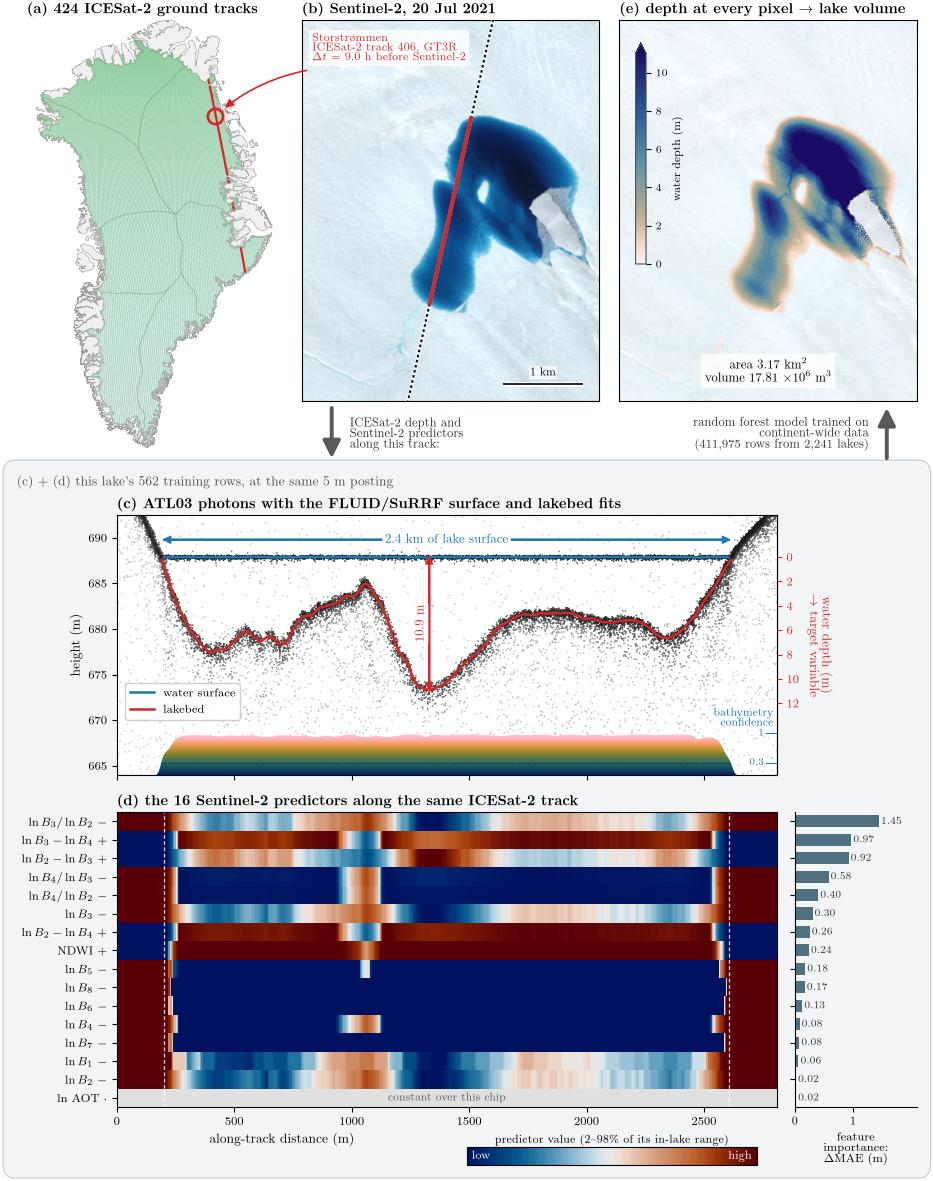

In [3]:
plt.close('all')

# ---- panel geometry, in inches. Declared before the map crop, which has to match the aspect
# of panels (b) and (e). Panel (a) runs from the top of the figure down past the flow band to
# the card, so the ground tracks get as much room as the layout allows.
FW, FH = 9.5, 12.2
TOP, RIGHT, L_A, L = FH - 0.45, FW - 0.25, 0.35, 1.25
CARD_L, CARD_R = 0.15, RIGHT + 0.10
S_H = 3.81                     # height of (b) and (e); their tops align with (a)
y_be = TOP - S_H
BAND_TOP, BAND_BOT = y_be - 0.04, y_be - 0.62
CARD_TOP = BAND_BOT - 0.02
H_A = TOP - (CARD_TOP + 0.04)
W_A = H_A / 1.73               # Greenland is 1.73x taller than wide, so this is width-limited
S_W = (RIGHT - L_A - W_A - 0.40) / 2
x_b = L_A + W_A + 0.20
x_e = x_b + S_W + 0.20

# Centre the two chips on the midpoint of the in-water part of the ground track, then size the
# window from the lake, widening whichever axis is needed to hit the panel aspect.
red = g[(g.depth > 0) & (g.conf > CONF_MIN)]
mid = red.iloc[int(np.argmin(np.abs(red.xatc.to_numpy() -
                                    (red.xatc.min() + red.xatc.max()) / 2)))]
cx, cy = float(mid.x), float(mid.y)
ys, xs = np.where(main)
wx, wy = rasterio.transform.xy(pred_transform, ys, xs)
need_x = np.abs(np.asarray(wx) - cx).max()
need_y = np.abs(np.asarray(wy) - cy).max()
half_x = max(need_x, need_y * S_W / S_H) * (1 + PAD_FRAC) * TRIM
half_y = half_x * S_H / S_W
map_xl, map_yl = (cx - half_x, cx + half_x), (cy - half_y, cy + half_y)

fig = plt.figure(figsize=(FW, FH))


def ax_in(x, y, w, h):
    """Axes placed by inches from the lower-left corner of the figure."""
    return fig.add_axes([x / FW, y / FH, w / FW, h / FH])


axA = ax_in(L_A, CARD_TOP + 0.04, W_A, H_A)
axB = ax_in(x_b, y_be, S_W, S_H)
axE = ax_in(x_e, y_be, S_W, S_H)
W_MAIN, W_BARS = 6.60, 1.22
axC = ax_in(L, CARD_TOP - 0.50 - 2.60, W_MAIN, 2.60)
axD = ax_in(L, 0.88, W_MAIN, 2.95)
axI = ax_in(L + W_MAIN + 0.18, 0.88, W_BARS, 2.95)

TITLE = dict(fontsize=10.5, loc='left', pad=5, fontweight='bold')
dnorm = Normalize(0, VMAX)

# ---------------------------------------------------------- (a) RGT map over Greenland
basins = gpd.read_file(f'{SHP}/GRE_basins_merged_GRIMP.shp')
coast = gpd.read_file(f'{SHP}/Greenland_coast.shp').to_crs(basins.crs)
coast = coast[coast.geometry.area > 1e8]
rgts = gpd.read_file(f'{SHP}/rgts_gris_clipped.shp').to_crs(basins.crs)
lake_pt = gpd.GeoSeries([gpd.points_from_xy([dp.lon.mean()], [dp.lat.mean()])[0]],
                        crs='EPSG:4326').to_crs(basins.crs)

coast.plot(ax=axA, fc='0.94', ec='0.62', lw=0.4, zorder=1)
basins.plot(ax=axA, fc='#dfeaf2', ec='0.72', lw=0.5, zorder=2)
# 424 tracks ~9.9 km apart cover ~30% of the ice sheet at this scale, so they are drawn light
rgts.plot(ax=axA, color=GREEN_532, lw=0.25, alpha=0.40, zorder=3)
this_rgt = rgts[rgts.rgt == RGT]
assert len(this_rgt) == 1, f'expected one line for RGT {RGT}, got {len(this_rgt)}'
this_rgt.plot(ax=axA, color=RED, lw=1.6, zorder=4)
axA.plot(lake_pt.x, lake_pt.y, 'o', ms=11, mfc='none', mec=RED, mew=2.0, zorder=6)
bx0, by0, bx1, by1 = basins.total_bounds
axA.set_xlim(bx0 - 70e3, bx1 + 70e3)
axA.set_ylim(by0 - 70e3, by1 + 70e3)
axA.set_aspect('equal', adjustable='datalim')
axA.set_xticks([])
axA.set_yticks([])
axA.patch.set_visible(False)       # otherwise it paints over the (c)+(d) card
for s in axA.spines.values():
    s.set_visible(False)
axA.set_title(bold(tex(f'(a)  {rgts.rgt.nunique()} ICESat-2 ground tracks')), **TITLE)

# ---------------------------------------------------------- (b) chip + ground track
axB.imshow(rgb, extent=chip_ext, origin='upper')
# over 3 km the ground track is straight to well under a pixel, so the segment's principal
# direction can be extended across the whole panel to show the track in context
P = np.column_stack([g.x.to_numpy(), g.y.to_numpy()])
ctr = P.mean(axis=0)
direction = np.linalg.svd(P - ctr, full_matrices=False)[2][0]
resid = np.abs((P - ctr) @ np.array([-direction[1], direction[0]])).max()
print(f'ground track straightness: max deviation from a line {resid:.2f} m over '
      f'{np.hypot(*(P[-1] - P[0])):.0f} m')
reach = 1.2 * np.hypot(2 * half_x, 2 * half_y)
trackline = np.vstack([ctr - reach * direction, ctr + reach * direction])
axB.plot(trackline[:, 0], trackline[:, 1], '-', color='w', lw=2.6, alpha=0.75, zorder=3)
axB.plot(trackline[:, 0], trackline[:, 1], ls=(0, (1.2, 1.3)), color='k', lw=1.5, zorder=4)
axB.plot(red.x, red.y, '-', color=RED, lw=2.8, zorder=5, solid_capstyle='butt')
axB.set_xlim(map_xl)
axB.set_ylim(map_yl)
axB.set_aspect('equal', adjustable='box')
axB.set_xticks([])
axB.set_yticks([])
axB.set_title(bold(tex('(b)  Sentinel-2, 20 Jul 2021')), **TITLE)
axB.text(0.035, 0.965, tex('Storstr\u00f8mmen') + f'\nICESat-2 track {RGT}, {GTX}\n'
         r'$\Delta t$ = 9.0 h before Sentinel-2', transform=axB.transAxes,
         fontsize=7.8, va='top', color=RED, zorder=10,
         bbox=dict(fc='w', alpha=0.82, ec='none', pad=2.5))

BAR = 1000.0
frac = BAR / (2 * half_x)
for col, lw in (('w', 3.5), ('k', 1.2)):
    axB.plot([0.945 - frac, 0.945], [0.045] * 2, transform=axB.transAxes, color=col, lw=lw,
             solid_capstyle='butt', zorder=20)
axB.text(0.945 - frac / 2, 0.062, f'{BAR/1000:.0f} km', transform=axB.transAxes, ha='center',
         va='bottom', fontsize=8, zorder=21, bbox=dict(fc='w', alpha=0.7, ec='none', pad=1))

# ---------------------------------------------------------- (e) gridded depth + volume
axE.imshow(rgb, extent=chip_ext, origin='upper', alpha=0.55)
imE = axE.imshow(np.where(water, depth_grid, np.nan), extent=chip_ext, origin='upper',
                 cmap=cmc.lapaz_r, norm=dnorm)
axE.set_xlim(map_xl)
axE.set_ylim(map_yl)
axE.set_aspect('equal', adjustable='box')
axE.set_xticks([])
axE.set_yticks([])
axE.set_title(bold(tex('(e)  depth at every pixel ') + r'$\rightarrow$' + tex(' lake volume')),
              **TITLE)
axE.text(0.5, 0.045, f'area {area/1e6:.2f} km$^2$\n'
         f'volume {vol/1e6:.2f} ' + r'$\times10^6$ m$^3$',
         transform=axE.transAxes, fontsize=9, va='bottom', ha='center',
         multialignment='center', bbox=dict(fc='w', alpha=0.82, ec='none', pad=3))
cbax = axE.inset_axes([0.055, 0.36, 0.035, 0.58])
cb = plt.colorbar(imE, cax=cbax, extend='max')
cbax.yaxis.set_ticks_position('right')
cbax.yaxis.set_label_position('right')
cb.set_label(tex('water depth (m)'), fontsize=8, labelpad=3)
cb.ax.tick_params(labelsize=7.5)
cb.outline.set_edgecolor('0.3')

# ---------------------------------------------------------- (c) photons + FLUID/SuRRF
# "signal" = photons FLUID/SuRRF actually attributed to the surface or the lakebed. A plain
# snr cut is no good here: snr > 0.5 reaches 704 m, but those are returns off the ice surface
# rising away from the lake, not lake photons, and including them squashes the transect.
signal = ph[(ph.prob_surf + ph.prob_bed) > 0.1]
YLIM = (signal.h.min() - Y_DROP, H0 + 4.6)
n_cut = int(((signal.h < YLIM[0]) | (signal.h > YLIM[1])).sum())
print(f'panel (c) y limits {YLIM[0]:.1f} - {YLIM[1]:.1f} m; '
      f'{n_cut} of {len(signal):,} surface/bed photons fall outside')
assert n_cut == 0, 'the y window clips photons assigned to the surface or the bed'

phs = ph[(ph.h > YLIM[0]) & (ph.h < YLIM[1])]
axC.scatter(phs.xatc, phs.h, s=1.6, c=np.clip(phs.snr, 0, 1), cmap='Greys',
            vmin=-0.4, vmax=1.1, lw=0, zorder=2)
sfit = dp[(dp.xatc >= SURF_EXT[0]) & (dp.xatc <= SURF_EXT[1])]
axC.plot(sfit.xatc, sfit.h_fit_surf, color=BLUE, lw=1.8, label=tex('water surface'), zorder=6)
axC.plot(wet.xatc, wet.h_fit_bed, color=RED, lw=1.8, label=tex('lakebed'), zorder=6)
axC.set_xlim(XLIM)
axC.set_ylim(YLIM)
axC.set_ylabel(tex('height (m)'), fontsize=9.5)
axC.tick_params(labelsize=8.5, labelbottom=False)
axC.legend(fontsize=8.5, loc='lower left', bbox_to_anchor=(0.004, 0.19), framealpha=0.92)
axC.set_title(bold(tex('(c)  ATL03 photons with the FLUID/SuRRF surface and lakebed fits')),
              **TITLE)

dax = axC.secondary_yaxis('right', functions=(lambda h: (H0 - h) / REFRACT,
                                              lambda d: H0 - d * REFRACT))
dax.set_ylabel(tex('water depth (m)') + '\n' + r'$\rightarrow$ target variable',
               color=RED, fontsize=9.5, rotation=-90, labelpad=24)
dax.set_yticks([0, 2, 4, 6, 8, 10, 12])
dax.tick_params(colors=RED, labelsize=8.5)
dax.spines['right'].set_color(RED)

arr_y = H0 + 1.9
for xy, xytext in ((SURF_EXT[0], SURF_EXT[1]), (SURF_EXT[1], SURF_EXT[0])):
    axC.annotate('', xy=(xy, arr_y), xytext=(xytext, arr_y), zorder=20,
                 arrowprops=dict(width=0.6, headwidth=5, headlength=5, color=BLUE))
axC.text(SURF_EXT.mean(), arr_y, tex(f'{LEN_SURF_KM:.1f} km of lake surface'), fontsize=8.8,
         ha='center', va='center', color=BLUE, zorder=21,
         bbox=dict(fc='w', alpha=1.0, ec='none', boxstyle='round,pad=0.2'))

y_bed = H0 - MAX_DEPTH * REFRACT
for xy, xytext in ((y_bed, H0), (H0, y_bed)):
    axC.annotate('', xy=(MAX_DEPTH_X, xy), xytext=(MAX_DEPTH_X, xytext), zorder=20,
                 arrowprops=dict(width=0.6, headwidth=5, headlength=5, color=RED))
axC.text(MAX_DEPTH_X - 14, (H0 + y_bed) / 2, f'{MAX_DEPTH:.1f} m', fontsize=9, rotation=90,
         ha='right', va='center', color=RED, zorder=21,
         bbox=dict(fc='w', alpha=0.85, ec='none', boxstyle='round,pad=0.2'))

# bathymetry confidence, a gradient-filled strip flush with the floor of the transect
CBASE, CH = YLIM[0], 4.6
confs = dp.conf.where(dp.depth > 0, 0.0)     # conf is 1 by construction where depth == 0
confs = confs.rolling(window=9, win_type='gaussian', min_periods=1, center=True).mean(std=2)
poly = axC.fill_between(dp.xatc, CBASE + CH * confs, CBASE, color='none', zorder=9)
try:
    grad = axC.imshow(np.linspace(0, 1, 256).reshape(-1, 1), cmap=cmc.batlow, aspect='auto',
                      origin='lower', extent=(XLIM[0], XLIM[1], CBASE, CBASE + CH), zorder=9)
    grad.set_clip_path(poly.get_paths()[0], transform=axC.transData)
except Exception as exc:                      # matplotlib API drift; a flat fill still reads
    print(f'gradient clip unavailable ({exc}); falling back to a solid fill')
    axC.fill_between(dp.xatc, CBASE + CH * confs, CBASE, color='#4a6d80', zorder=9)
x_sc = XLIM[1]
axC.plot([XLIM[0], x_sc], [CBASE] * 2, color=BLUE, lw=0.8, zorder=11)
axC.plot([x_sc] * 2, [CBASE, CBASE + CH], color=BLUE, lw=0.8, zorder=11)
for tick in (0.0, CONF_MIN, 1.0):
    yt = CBASE + CH * tick
    axC.plot([x_sc - 45, x_sc], [yt] * 2, color=BLUE, lw=0.8, zorder=11)
    if tick:
        axC.text(x_sc - 55, yt, f'{tick:g}', fontsize=7.2, color=BLUE, ha='right',
                 va='center', zorder=20)
    if tick == CONF_MIN:
        # only where it actually falls inside the filled area, so it does not run on as a
        # rule across stretches with no bathymetry at all
        inside = (confs >= CONF_MIN).to_numpy()
        axC.plot(np.where(inside, dp.xatc, np.nan), np.where(inside, yt, np.nan),
                 color='k', lw=0.6, ls=':', zorder=12)
axC.text(x_sc - 15, CBASE + CH + 0.6, tex('bathymetry\nconfidence'), fontsize=8, color=BLUE,
         ha='right', va='bottom', zorder=13, multialignment='right',
         bbox=dict(fc='w', alpha=0.75, ec='none', pad=1.5))

# ---------------------------------------------------------- (d) predictor heatmap
# vik is diverging, so its midpoint is near-white - the same colour matplotlib paints a NaN
# row. Give the constant AOT row an explicit grey so it cannot read as a mid-range value.
heat_cmap = cmc.vik.with_extremes(bad='0.88')
im = axD.imshow(Mn, aspect='auto', cmap=heat_cmap, vmin=0, vmax=1, interpolation='nearest',
                extent=(XLIM[0], XLIM[1], len(feats) - 0.5, -0.5))
axD.set_xlim(XLIM)
axD.set_yticks(range(len(feats)))
axD.set_yticklabels(ylabels, fontsize=8.6)
axD.set_xlabel(tex('along-track distance (m)'), fontsize=9.5, x=0.25)
axD.tick_params(labelsize=8.5)
for xb in (SURF_EXT[0], SURF_EXT[1]):
    axD.axvline(xb, color='w', ls=(0, (3, 2)), lw=0.9, alpha=0.85)
if 'AOT_log' in feats:
    axD.text(0.5, feats.index('AOT_log'), tex('constant over this chip'), ha='center',
             va='center', transform=axD.get_yaxis_transform(), fontsize=7.5, color='0.35',
             style='italic')
axD.set_title(bold(tex('(d)  the 16 Sentinel-2 predictors along the same ICESat-2 track')),
              **TITLE)

cax = axD.inset_axes([0.53, -0.195, 0.44, 0.060])
plt.colorbar(im, cax=cax, orientation='horizontal')
cax.set_xticks([])
# vik runs dark blue to dark red, so white reads at both ends
for frac_x, labtxt, ha in ((0.018, 'low', 'left'), (0.982, 'high', 'right')):
    cax.text(frac_x, 0.5, tex(labtxt), transform=cax.transAxes, ha=ha, va='center',
             fontsize=8.5, color='w')
cax.set_title(tex('predictor value (2\u201398% of its in-lake range)'), fontsize=7.8, pad=3)

axI.barh(range(len(feats)), imp.imp_perm_dmae, color='#50707f', height=0.66)
for i, v in enumerate(imp.imp_perm_dmae):
    axI.text(v + 0.035, i, f'{v:.2f}', va='center', fontsize=7.4, color='0.2')
axI.set_xlim(0, imp.imp_perm_dmae.max() * 1.45)
axI.set_ylim(len(feats) - 0.5, -0.5)
axI.patch.set_visible(False)
axI.tick_params(labelleft=False, labelsize=8)
axI.set_xticks([0, 1])
axI.set_xlabel(tex('feature\nimportance:') + '\n' + r'$\Delta$MAE (m)', fontsize=8.5)
for s in ('top', 'right'):
    axI.spines[s].set_visible(False)

# ---------------------------------------------------------- the flow between the panels
fx, fy = (lambda x: x / FW), (lambda y: y / FH)

card = FancyBboxPatch((fx(CARD_L), fy(0.22)),
                      fx(CARD_R) - fx(CARD_L), fy(CARD_TOP) - fy(0.22),
                      boxstyle='round,pad=0.004,rounding_size=0.012',
                      transform=fig.transFigure, fc='#f2f4f6', ec='#c8d0d6', lw=0.9, zorder=0)
fig.add_artist(card)

FLOW = dict(transform=fig.transFigure, arrowstyle='-|>', mutation_scale=26, lw=2.8,
            color='0.35', zorder=5)
x_down = x_b + 0.30
fig.add_artist(FancyArrowPatch((fx(x_down), fy(BAND_TOP)), (fx(x_down), fy(BAND_BOT + 0.02)),
                               **FLOW))
fig.text(fx(x_down + 0.18), fy((BAND_TOP + BAND_BOT) / 2),
         tex('ICESat-2 depth and\nSentinel-2 predictors\nalong this track:'), fontsize=8.6,
         color='0.2', ha='left', va='center')

x_up = x_e + S_W - 0.30
fig.add_artist(FancyArrowPatch((fx(x_up), fy(BAND_BOT + 0.02)), (fx(x_up), fy(BAND_TOP)),
                               **FLOW))
fig.text(fx(x_up - 0.18), fy((BAND_TOP + BAND_BOT) / 2),
         tex(f'random forest model trained on\ncontinent-wide data\n'
             f'({N_TRAIN:,} rows from {N_LAKES:,} lakes)'), fontsize=8.6, color='0.2',
         ha='right', va='center')

fig.text(fx(CARD_L + 0.10), fy(CARD_TOP - 0.17),
         tex(f'(c) + (d)  this lake\u2019s {len(tl)} training rows, '
             'at the same 5 m posting'),
         fontsize=9.5, color='0.3', style='italic', ha='left', va='center', zorder=6)

# The cross-panel arrow is a figure artist, so neither axes clips it. Panel (a) uses
# adjustable='datalim', so its data transform is only final once the figure has been drawn --
# move this above the draw() and the arrow silently lands in the wrong place.
fig.canvas.draw()
_r = fig.canvas.get_renderer()
_lab_left = min(t.get_window_extent(renderer=_r).x0
                for t in axD.get_yticklabels()) / fig.dpi
print(f'panel (d) labels reach {_lab_left:.2f} in from the left edge; '
      f'the card starts at {CARD_L:.2f} in (gutter {L - CARD_L:.2f} in)')
assert _lab_left > CARD_L + 0.02, \
    f'the predictor labels overflow the card: {_lab_left:.2f} in vs card at {CARD_L:.2f} in'

to_fig = fig.transFigure.inverted().transform
head = to_fig(axA.transData.transform((lake_pt.x.iloc[0], lake_pt.y.iloc[0])))
tail = to_fig(axB.transAxes.transform((0.030, 0.87)))
fig.add_artist(FancyArrowPatch(tuple(tail), tuple(head), transform=fig.transFigure,
                               arrowstyle='-|>', mutation_scale=12, lw=1.2, color=RED,
                               shrinkA=3, shrinkB=9, connectionstyle='arc3,rad=0.14',
                               zorder=10))

figfn = 'figures/fig02_methods-explainer.jpg'
for savefn in [figfn, figfn.replace('.jpg', '.pdf')]:
    fig.savefig(savefn, dpi=300, bbox_inches='tight', pad_inches=0.03)
fig.savefig(figfn.replace('.jpg', '_lowres.jpg'), dpi=100, bbox_inches='tight', pad_inches=0.03)
plt.close(fig)
display(Image(figfn.replace('.jpg', '_lowres.jpg')))
